In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kendalltau
import json
import re

In [2]:
model = "Qwen/Qwen2.5-Coder-32B"
short_model_name = model.split("/")[-1]

model_results_dir = f"../model_results/{short_model_name}"
model_pairwise_results_dir = os.path.join(model_results_dir, "pairwise_analysis")
model_pairwise_comparisons_dir = os.path.join(model_pairwise_results_dir, "pairwise_comparisons")
model_data_driven_comparisons_dir = os.path.join(model_results_dir, "data_driven_aois_comparison")

output_dir = "RQ2"

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

In [3]:
analysis_df = pd.read_csv(os.path.join(model_pairwise_comparisons_dir, "eeg_perplexity_analysis.csv"))

In [4]:
def create_eeg_perplexity_correlation_plots(analysis_df):
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)

    # read overlapping results from aoi_comparison
    file_path = os.path.join(model_data_driven_comparisons_dir, "aoi_overlap_snippet_lists.json")
    with open(file_path, 'r') as f:
        aoi_comparison = json.load(f)

    overlapping_clean = aoi_comparison["overlap"]["clean"]
    overlapping_obf = aoi_comparison["overlap"]["obf"]
    non_overlapping_clean = aoi_comparison["no_overlap"]["clean"]
    non_overlapping_obf = aoi_comparison["no_overlap"]["obf"]

    correlation_results = []

    clean_df = pd.DataFrame({
        'file': analysis_df['clean_file'],
        'mean_eeg': analysis_df['clean_mean_eeg'],
        'Max AOI Perplexity': analysis_df['clean_Max AOI Perplexity']
    })

    obf_df = pd.DataFrame({
        'file': analysis_df['obf_file'],
        'mean_eeg': analysis_df['obf_mean_eeg'],
        'Max AOI Perplexity': analysis_df['obf_Max AOI Perplexity']
    })

    # Step 2: Concatenate both
    combined_df = pd.concat([clean_df, obf_df], ignore_index=True)

    # Automatically detect relevant columns
    perplexity_metrics = [col for col in combined_df.columns if col.endswith('Max AOI Perplexity')]
    eeg_metrics = [col for col in combined_df.columns if col.endswith('mean_eeg')]

    def make_numbered_mask(df, base_list):
        # Build regex for all base patterns, matching only files that start with the base and end with -1..-10 before extension
        regexes = [rf"^{re.escape(base)}-(?:[1-9]|10)" for base in base_list]
        combined_regex = "|".join(regexes)
        return df['file'].str.contains(combined_regex, regex=True)

    # Define subsets: full, clean, and obf
    subsets = {
        "full": combined_df,
        "clean": combined_df[combined_df['file'].str.contains("clean", case=False, na=False)],
        "obf": combined_df[combined_df['file'].str.contains("obf", case=False, na=False)],
        "overlapping_clean": combined_df[combined_df['file'].isin(overlapping_clean)],
        "overlapping_obf": combined_df[combined_df['file'].isin(overlapping_obf)],
        "non_overlapping_clean": combined_df[combined_df['file'].isin(non_overlapping_clean)],
        "non_overlapping_obf": combined_df[combined_df['file'].isin(non_overlapping_obf)]
    }

    for subset_name, subset_df in subsets.items():
        for perp_metric in perplexity_metrics:
            safe_perp_name = perp_metric.replace(' ', '_').lower()
            for eeg_metric in eeg_metrics:
                eeg_prefix = eeg_metric.replace('_eeg', ' ').capitalize() + 'EEG Signal'
                plt.figure(figsize=(8, 4))
                x_vals = subset_df[perp_metric]
                y_vals = pd.to_numeric(subset_df[eeg_metric], errors='coerce')

                # Filter out NaN
                valid_indices = x_vals.notna() & y_vals.notna()
                x_vals = x_vals[valid_indices].reset_index(drop=True)
                y_vals = y_vals[valid_indices].reset_index(drop=True)

                if x_vals.empty or y_vals.empty:
                    print(f"[{subset_name}] Skipping {eeg_prefix} vs {perp_metric} due to empty data.")
                    continue

                plt.scatter(x_vals, y_vals, s=100, alpha=0.6, label='Data Points')

                # Log scale
                plt.xscale('log', base=10)
                valid_x = x_vals[x_vals > 0]
                if valid_x.empty:
                    continue
                min_exp = 0
                max_exp = 7
                xticks = [10 ** i for i in range(min_exp, max_exp + 1)]
                xtick_labels = [r"$10^{%d}$" % i for i in range(min_exp, max_exp + 1)]
                plt.xticks(xticks, xtick_labels)
                plt.xlim(min(xticks), max(xticks))
                # Set y-axis limits -10**-5 to 10**-5
                plt.ylim(-1e-5, 1e-5)

                # Trend line in log space
                x_log = np.log(valid_x)
                y_trimmed = y_vals.loc[valid_x.index]
                if len(x_log) > 1:
                    # Linear fit
                    z = np.polyfit(x_log, y_trimmed, 1)
                    p = np.poly1d(z)
                    x_range = np.linspace(min(x_log), max(x_log), 100)
                    plt.plot(np.exp(x_range), p(x_range), "r--", alpha=0.7, label='Trend Line')

                    # Correlations
                    spearman_r, spearman_p = spearmanr(x_vals, y_vals)
                else:
                    spearman_r = spearman_p = np.nan

                correlation_results.append({
                    'subset': subset_name,
                    'eeg_metric': eeg_metric,
                    'perplexity_metric': perp_metric,
                    'spearman_r': spearman_r,
                    'spearman_p': spearman_p
                })

                plt.title(f'{subset_name.upper()}: {eeg_prefix} vs {perp_metric} (Log Scale)\n'
                          f'Spearman r={spearman_r:.3f} (p={spearman_p:.3f})'
                          )
                plt.xlabel(f'{perp_metric} (Log Scale)')
                plt.ylabel(f'{eeg_prefix}')
                plt.grid(True, alpha=0.3)
                plt.legend(title="AOI Category", bbox_to_anchor=(1.05, 1), loc='upper left')

                filename = f"{eeg_metric}_vs_{safe_perp_name}_{subset_name}_log.pdf"
                plt.savefig(os.path.join(output_dir, filename), bbox_inches='tight')

                plt.close()

    correlation_df = pd.DataFrame(correlation_results)
    correlation_csv_path = os.path.join(output_dir, "correlation_statistics_by_subset.csv")
    correlation_df.to_csv(correlation_csv_path, index=False)
    print(f"Correlation statistics saved to {correlation_csv_path}")

    return analysis_df, correlation_df

In [5]:
create_eeg_perplexity_correlation_plots(analysis_df)

Correlation statistics saved to RQ2/correlation_statistics_by_subset.csv


(   pair_id   clean_file   obf_file  clean_mean_eeg  obf_mean_eeg  \
 0     9-v1   9-clean-v1   9-obf-v1    1.248908e-06  5.562963e-06   
 1    18-v1  18-clean-v1  18-obf-v1   -7.911899e-08  1.340195e-06   
 2    16-v1  16-clean-v1  16-obf-v1   -1.503979e-05  3.366924e-07   
 3    12-v1  12-clean-v1  12-obf-v1   -1.954570e-06  2.100476e-06   
 4    62-v1  62-clean-v1  62-obf-v1   -5.508339e-06  3.731484e-06   
 ..     ...          ...        ...             ...           ...   
 67    4-v2   4-clean-v2   4-obf-v2    4.700814e-06  3.200035e-06   
 68   16-v2  16-clean-v2  16-obf-v2   -7.206880e-06 -5.135830e-06   
 69   12-v2  12-clean-v2  12-obf-v2    3.439026e-08  8.078507e-06   
 70   18-v2  18-clean-v2  18-obf-v2    2.789241e-07  2.334797e-06   
 71    9-v2   9-clean-v2   9-obf-v2   -2.306926e-06  1.133459e-06   
 
     mean_eeg_diff  clean_max_eeg  obf_max_eeg  max_eeg_diff  \
 0        0.000004   1.466152e-05     0.000024      0.000009   
 1        0.000001   2.007078e-05     0.00

In [6]:
plt.rcParams.update({'font.size': 11, 'font.family': 'sans-serif'})

In [7]:
def plot_clean_vs_confusing_separately(analysis_df):
    # Remove outlier pair_id '16-v1' from clean snippets
    clean_df = analysis_df[analysis_df['pair_id'] != '16-v1']

    # Extract and rescale EEG values to bring them to µV range
    clean_x = pd.to_numeric(clean_df['clean_Max AOI Perplexity'], errors='coerce')
    clean_y = pd.to_numeric(clean_df['clean_mean_eeg'], errors='coerce') * 1e6

    obf_x = pd.to_numeric(analysis_df['obf_Max AOI Perplexity'], errors='coerce')
    obf_y = pd.to_numeric(analysis_df['obf_mean_eeg'], errors='coerce') * 1e6

    # Keep only positive values
    clean_mask = clean_x > 0
    obf_mask = obf_x > 0

    clean_x, clean_y = clean_x[clean_mask], clean_y[clean_mask]
    obf_x, obf_y = obf_x[obf_mask], obf_y[obf_mask]

    # Unified x-axis range for both plots
    combined_min = min(clean_x.min(), obf_x.min())
    combined_max = max(clean_x.max(), obf_x.max())
    combined_min_exp = 0
    combined_max_exp = int(np.ceil(np.log10(combined_max)))
    xticks = [10 ** i for i in range(combined_min_exp, combined_max_exp + 1)]

    fig, axs = plt.subplots(1, 2, figsize=(6, 2), sharey=True)

    def plot_one(ax, x, y, snippet_type):
        color = "#1F77B4" if snippet_type == "clean" else "#D62728"
        x_log = np.log(x)
        coeffs = np.polyfit(x_log, y, 1)
        poly_fn = np.poly1d(coeffs)
        x_range = np.linspace(np.log(combined_min), np.log(combined_max), 100)
        ax.plot(np.exp(x_range), poly_fn(x_range), linestyle='-', color=color, linewidth=1)

        ax.scatter(x, y, color=color, s=25, alpha=0.6)

        ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

        ax.set_xscale('log', base=10)
        ax.set_xlabel("Max AOI Perplexity")

        ax.set_xticks(xticks)
        ax.set_xticklabels([f"$10^{i}$" for i in range(combined_min_exp, combined_max_exp + 1)])

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        def format_p(p):
            return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

        spearman_r, spearman_p = spearmanr(x, y)
        textstr = (
            f"Spearman $\\rho$ = {spearman_r:.2f} \n ({format_p(spearman_p)})\n"
        )
        ax.text(1.05, -0.1, textstr, transform=ax.transAxes,
                verticalalignment='bottom', horizontalalignment='right',
                bbox=dict(
                    facecolor='white',
                    edgecolor='none',
                    alpha=0,
                    pad=2
                ))

    axs[0].set_ylabel(r"Mean FRP ($\mu$V)")
    plot_one(axs[0], obf_x, obf_y, snippet_type='confusing')
    plot_one(axs[1], clean_x, clean_y, snippet_type='clean')

    plt.tight_layout()
    filename = f"{output_dir}/clean_vs_confusing_mean_eeg_max_ppl.pdf"
    plt.savefig(filename, bbox_inches='tight', dpi=300, pad_inches=0)
    plt.show()

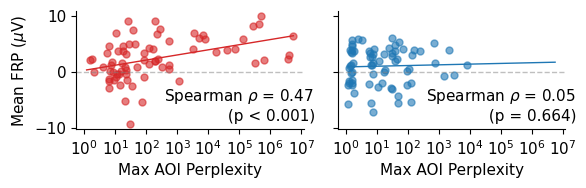

In [8]:
plot_clean_vs_confusing_separately(analysis_df)